# Network analysis of three web scraping methods
**Project:** Analyzing Website Data Collection Efficiency and Network Behavior Using Multiple Web Scraping Techniques
**Team:** Jana Alamir, Rim Zoghbi
**Data:** English Premier League 2023-2024, 380 matches, from TheSportsDB (free V1 API and website)
**Environment:** Windows + WSL2 Ubuntu, Python 3.14, requests, BeautifulSoup, Selenium (headless Chrome)

This notebook compares the API, BeautifulSoup and Selenium scrapers on time, requests, bandwidth and latency,
then analyses their network behaviour with ss, nload, iftop, tcpdump and Wireshark, and tests security measures (ufw, Tor).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# All runs ever recorded (history)
metrics = pd.read_csv("data/metrics.csv")
print("All recorded runs:")
display(metrics)

# Keep only the latest run of each method (the final runs)
final = metrics.groupby("method").tail(1).set_index("method")
final = final.loc[["api", "bs4", "selenium", "api_threaded_4", "api_tor"]]
print("Final runs used in the analysis:")
final

All recorded runs:


,method,time_s,requests,bandwidth_kb,avg_latency_ms,rows
0,api,17.52,40,661.35,435.1,380
1,bs4,32.63,38,1906.61,829.7,380
2,selenium,557.62,2176,72524.88,5136.1,380
3,api_threaded_4,362.84,56,772.45,194.5,380
4,api,9.26,42,675.24,217.6,380
5,bs4,22.99,38,1906.61,573.8,380
6,selenium,304.72,2175,72524.12,3477.6,380
7,api_tor,35.96,39,654.41,918.1,380


Final runs used in the analysis:


,time_s,requests,bandwidth_kb,avg_latency_ms,rows
method,,,,,
api,9.26,42,675.24,217.6,380
bs4,22.99,38,1906.61,573.8,380
selenium,304.72,2175,72524.12,3477.6,380
api_threaded_4,362.84,56,772.45,194.5,380
api_tor,35.96,39,654.41,918.1,380


## 1. Comparison of the three scraping methods
All three scrapers collected exactly the same 380 matches (verified with `equals()`).
These are the final runs, made back-to-back on 21 Nov 2026 so that all methods faced the same network conditions.

Ratio compared with the API (API = 1):


,time_s,requests,bandwidth_kb,avg_latency_ms
method,,,,
api,1.0,1.0,1.0,1.0
bs4,2.5,0.9,2.8,2.6
selenium,32.9,51.8,107.4,16.0


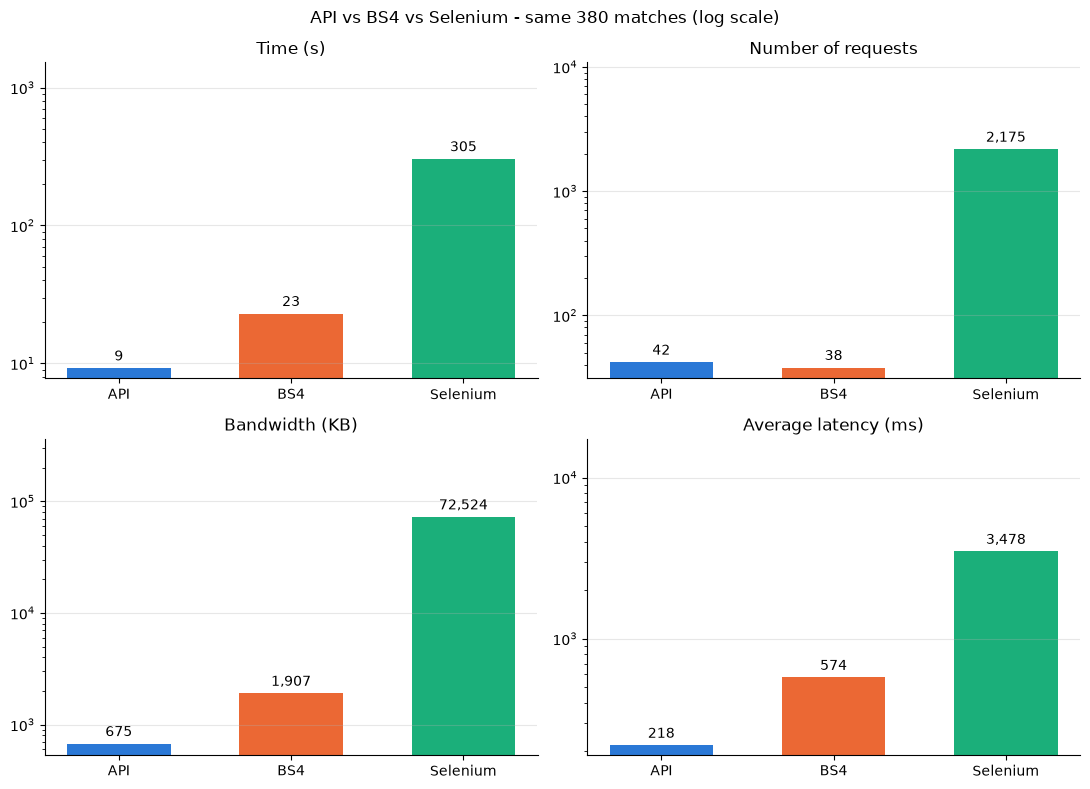

In [2]:
import os
os.makedirs("figures", exist_ok=True)

# The 3 scraping methods, in a fixed order, each with its own fixed color
METHODS = ["api", "bs4", "selenium"]
LABELS = {"api": "API", "bs4": "BS4", "selenium": "Selenium"}
COLORS = {"api": "#2a78d6", "bs4": "#eb6834", "selenium": "#1baf7a"}

methods = final.loc[METHODS]

# How many times more than the API? (API = 1)
ratios = (methods / methods.loc["api"]).round(1)
print("Ratio compared with the API (API = 1):")
display(ratios.drop(columns="rows"))

charts = [
    ("time_s", "Time (s)"),
    ("requests", "Number of requests"),
    ("bandwidth_kb", "Bandwidth (KB)"),
    ("avg_latency_ms", "Average latency (ms)"),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, (column, title) in zip(axes.flat, charts):
    values = methods[column]
    bars = ax.bar([LABELS[m] for m in METHODS], values,
                  color=[COLORS[m] for m in METHODS], width=0.6)
    ax.set_yscale("log")                       # values differ by up to 100x
    ax.set_ylim(top=values.max() * 5)          # room above the bars for the labels
    ax.bar_label(bars, labels=[f"{v:,.0f}" for v in values], padding=3)
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("API vs BS4 vs Selenium - same 380 matches (log scale)")
fig.tight_layout()
fig.savefig("figures/methods_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Bandwidth measured in Python vs bytes on the wire (Wireshark)
Python counts the decompressed response bodies. Wireshark counts every byte that crossed the network:
compressed bodies plus TCP/IP/TLS overhead, DNS, and traffic the scraper itself never sees
(for Selenium, Chrome's own background downloads).

,requests,python_kb,wire_kb,tcp_connections,wire_vs_python
api,42,675.24,512.0,42,0.76
bs4,38,1906.61,711.4,38,0.37
selenium,2175,72524.12,101610.7,29,1.40
api_tor,39,654.41,703.5,2,1.08


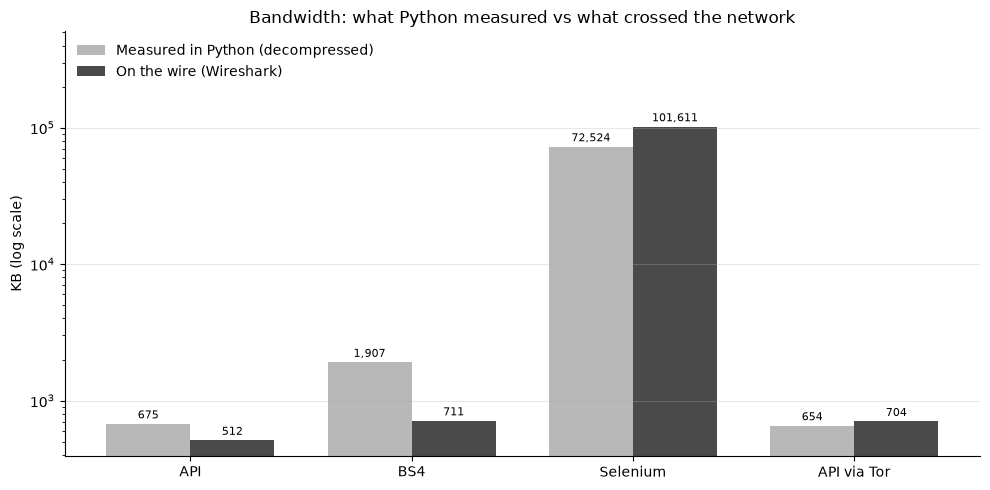

In [3]:
# Bytes on the wire, from Wireshark (Statistics -> Capture File Properties)
wire_bytes = pd.Series({"api": 524335, "bs4": 728509, "selenium": 104049399, "api_tor": 720420})
# TCP connections, from Wireshark (Statistics -> Conversations -> TCP tab)
tcp_connections = pd.Series({"api": 42, "bs4": 38, "selenium": 29, "api_tor": 2})

network = pd.DataFrame({
    "requests": final.loc[wire_bytes.index, "requests"],
    "python_kb": final.loc[wire_bytes.index, "bandwidth_kb"],
    "wire_kb": (wire_bytes / 1024).round(1),
    "tcp_connections": tcp_connections,
})
network["wire_vs_python"] = (network["wire_kb"] / network["python_kb"]).round(2)
display(network)

labels = ["API", "BS4", "Selenium", "API via Tor"]
x = list(range(len(network)))
width = 0.38

fig, ax = plt.subplots(figsize=(10, 5))
bars_python = ax.bar([i - width / 2 for i in x], network["python_kb"], width,
                     label="Measured in Python (decompressed)", color="#b8b8b8")
bars_wire = ax.bar([i + width / 2 for i in x], network["wire_kb"], width,
                   label="On the wire (Wireshark)", color="#4a4a4a")
ax.bar_label(bars_python, fmt="{:,.0f}", padding=2, fontsize=8)
ax.bar_label(bars_wire, fmt="{:,.0f}", padding=2, fontsize=8)

ax.set_yscale("log")
ax.set_ylim(top=network["wire_kb"].max() * 5)
ax.set_xticks(x, labels)
ax.set_ylabel("KB (log scale)")
ax.set_title("Bandwidth: what Python measured vs what crossed the network")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig("figures/python_vs_wire.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Experiments: multithreading and Tor (variants of the API scraper)
- **api_threaded_4**: 4 threads, no delay between requests.
- **api_tor**: the same API scraper, with every request sent through Tor.

Time is compared as *real elapsed time* (start to finish). For api and api_tor it comes from the Wireshark capture duration,
because their `time_s` in metrics.csv excludes waiting. The number of 429 responses is `requests - 38`
(38 rounds; none of these runs had network errors).

,real_elapsed_s,requests,rate_limited_429,avg_latency_ms
api,554.30,42,4,217.6
api_threaded_4,362.84,56,18,194.5
api_tor,410.30,39,1,918.1


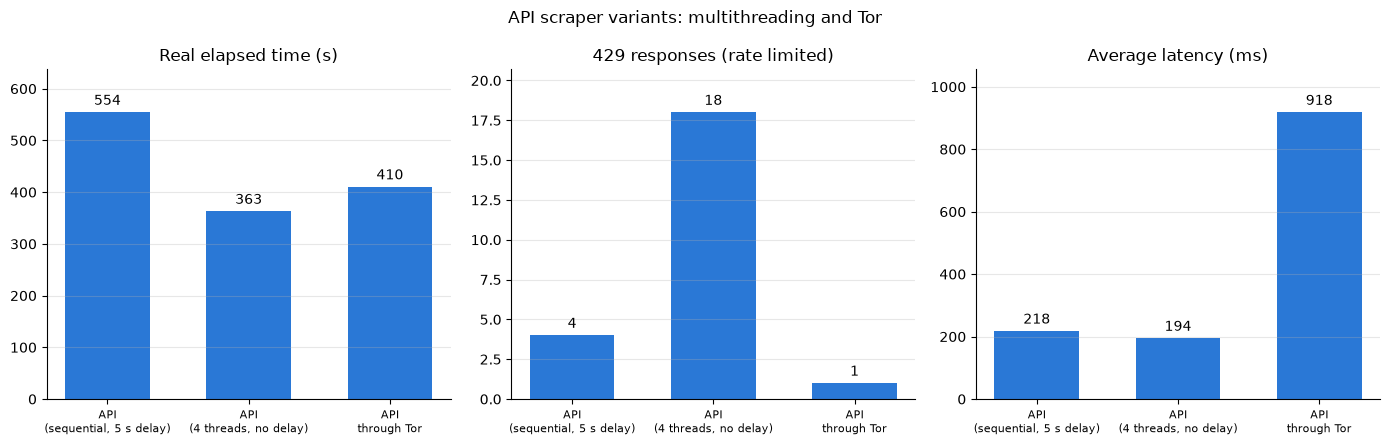

In [4]:
VARIANTS = ["api", "api_threaded_4", "api_tor"]
VARIANT_LABELS = ["API\n(sequential, 5 s delay)", "API\n(4 threads, no delay)", "API\nthrough Tor"]

experiments = pd.DataFrame({
    "real_elapsed_s": pd.Series({"api": 554.3, "api_threaded_4": 362.84, "api_tor": 410.3}),
    "requests": final.loc[VARIANTS, "requests"],
    "rate_limited_429": final.loc[VARIANTS, "requests"] - 38,
    "avg_latency_ms": final.loc[VARIANTS, "avg_latency_ms"],
})
display(experiments)

charts = [
    ("real_elapsed_s", "Real elapsed time (s)"),
    ("rate_limited_429", "429 responses (rate limited)"),
    ("avg_latency_ms", "Average latency (ms)"),
]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, (column, title) in zip(axes, charts):
    values = experiments[column]
    bars = ax.bar(VARIANT_LABELS, values, color="#2a78d6", width=0.6)
    ax.bar_label(bars, labels=[f"{v:,.0f}" for v in values], padding=3)
    ax.set_ylim(top=values.max() * 1.15)
    ax.set_title(title)
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("API scraper variants: multithreading and Tor")
fig.tight_layout()
fig.savefig("figures/experiments_threading_tor.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Network observations
### 4.1 TCP connections with `ss -tanp '( dport = :443 )'`
<img src="screenshots/ss_api.png" width="700">

**API:** every request opens a new TCP connection to Cloudflare (172.67.72.25), each with a new local port. After closing, each one stays in TIME-WAIT for about 60 s, so `requests.get()` does not reuse connections.

<img src="screenshots/ss_selenium.png" width="700">

**Selenium:** about 8 simultaneous connections owned by the `chrome` process (not `python`), to Cloudflare and Google servers. This is why the PDF's `ss -t -a | grep python` alone does not show Selenium's traffic.

### 4.2 Live bandwidth with `nload` and `iftop`
<img src="screenshots/nload_bs4.png" width="600"> <img src="screenshots/nload_selenium.png" width="600">

**nload:** BS4 peaks at about 14 KB/s (one 50 KB page every 5 s). Selenium saturates the connection at about 1,800 KB/s, about 130 times more.

<img src="screenshots/iftop_selenium.png" width="700">

**iftop (Selenium, per host):** the largest share of traffic came from a Google server, about 5 times more than from TheSportsDB itself. Reverse DNS names ending in `1e100.net` confirm Google.

### 4.3 Packet captures (tcpdump + Wireshark): conversations and protocols
<img src="screenshots/ws_conv_api.png" width="700">
<img src="screenshots/ws_conv_bs4.png" width="700">

**API and BS4:** one TCP connection and one DNS query per request (42 and 38). The DNS answer contains several Cloudflare IPs, and the connections alternate between them (DNS load balancing).

<img src="screenshots/ws_conv_selenium.png" width="700">
<img src="screenshots/ws_conv_selenium_udp.png" width="700">
<img src="screenshots/ws_protocols_selenium.png" width="700">

**Selenium:** only 29 TCP connections for 2,175 requests (connection reuse and HTTP/2 multiplexing). About 60% of the bytes used QUIC (HTTP/3 over UDP 443), which Chrome uses automatically; `requests` only speaks HTTP/1.1.

### 4.4 Identifying the servers: DNS, TLS Server Name (SNI), plain HTTP
<img src="screenshots/ws_dns_api.png" width="600">

**DNS:** www.thesportsdb.com resolves to 3 Cloudflare addresses (the IPv6 addresses embed the IPv4 ones: `ac43:4819` = 172.67.72.25).

<img src="screenshots/ws_sni_selenium.png" width="800">
<img src="screenshots/ws_http_chrome.png" width="800">

**Selenium:** besides TheSportsDB (`r2.thesportsdb.com` for images), the browser contacted Google Ads, Cloudflare analytics, and Chrome's own services. The largest single flow (43 MB over QUIC) was `optimizationguide-pa.googleapis.com`, Chrome downloading its own machine-learning models, and 5 MB of plain HTTP were Chrome component updates (`.crx3` files). About half of Selenium's traffic came from the browser itself, not from the website.

### 4.5 Traffic over time (Wireshark I/O graphs, bytes per second)
<img src="screenshots/ws_io_bs4.png" width="700">

**BS4:** one small burst every 5 seconds: our rate limiting is visible on the network.

<img src="screenshots/ws_io_api.png" width="700">

**API:** bursts of about 12 requests followed by about 2 minutes of silence: the real quota of the free API key, much lower than the documented 30 requests per minute.

<img src="screenshots/ws_io_selenium.png" width="700">

**Selenium:** until about 285 s the connection is saturated by Chrome's 43 MB background download (13.5 s + 271.8 s = 285.3 s), which slows down the page loads. After that, each page appears as a separate burst.

### 4.6 Security: blocking HTTPS with ufw
<img src="screenshots/ufw_rules.png" width="600">
<img src="screenshots/ufw_ss_blocked.png" width="700">

| ufw rule | Firewall behaviour | One HTTPS request |
|---|---|---|
| `deny out to any port 443` | drops packets silently (connection stays in SYN-SENT) | failed after 45.1 s (3 IPv4 addresses x 15 s timeout) |
| `reject out to any port 443` | refuses immediately | failed after 0.1 s |
| `allow out to any port 443` | lets traffic through | status 200 after 0.3 s |

<img src="screenshots/ufw_reject.png" width="700">
<img src="screenshots/ufw_allow.png" width="700">

`deny` hides the firewall from the client but makes it wait; `reject` gives immediate feedback. Our scrapers survive both thanks to their network-error handling.

### 4.7 Security: scraping through Tor
<img src="screenshots/ws_tor_dns.png" width="600">
<img src="screenshots/ws_tor_conv.png" width="700">
<img src="screenshots/ws_tor_props.png" width="500">

Through Tor there is no DNS query and no connection to TheSportsDB at all: only 2 encrypted connections to Tor relays. Our network sees that we use Tor, but not which site we scrape. The cost: about 4 times the latency and about 48% more bytes per request.

## 5. Conclusion and recommendation

| | API | BS4 | Selenium |
|---|---|---|---|
| Time (vs API) | 1x | 2.5x | 33x |
| Bandwidth in Python (vs API) | 1x | 2.8x | 107x |
| Bytes on the wire | 512 KB | 711 KB | 101,611 KB |
| Requests | 38 (+4 retries) | 38 | 2,175 |
| Rate limited (429) | yes, ~12 requests then ~2 min block | no | no |

**Recommended method: the API**, with a polite delay between requests. It is the fastest, the lightest and returns
structured data (JSON) that needs no parsing. Its weakness in our case is the free shared key, which was rate-limited
well below its documented limit, so the scraper must respect the limit and retry with back-off.

**BS4 is the reliable fallback.** It is about 2.5 times slower and its pages are about 3 times heavier, but HTML
compresses very well (only 1.4 times the API's bytes on the wire), and the website was never rate-limited.

**Selenium should only be used when a page needs JavaScript.** It was 33 times slower, made 57 requests per page,
and about half of its traffic came from Chrome itself (background downloads), not from the website.

**Optimization findings:**
- Multithreading did not help: the bottleneck is the server's rate limit, not waiting for responses. With 4 threads,
  18 requests were refused.
- `requests.get()` opens a new TCP + TLS connection and makes a new DNS query for every request. The 42 TLS
  handshakes alone were about 13% of the API's traffic, so reusing one connection (`requests.Session()`) is the next optimization.
- For Selenium, turning off Chrome's background networking and image loading would remove much of its traffic (not tested here).

**Security findings:**
- ufw `deny` makes a blocked scraper hang (45 s per request), `reject` makes it fail at once (0.1 s); network-error
  handling keeps the scraper from crashing in both cases.
- Tor hides which site we scrape from our own network, at the cost of about 4 times the latency and 48% more bytes.